---
title: "Dimensionality reduction in a real dataset"
output: html_document
---

In [4]:
library(dplyr)
library(scatterplot3d) # 3d plots
library(mvtnorm) # generate spheres

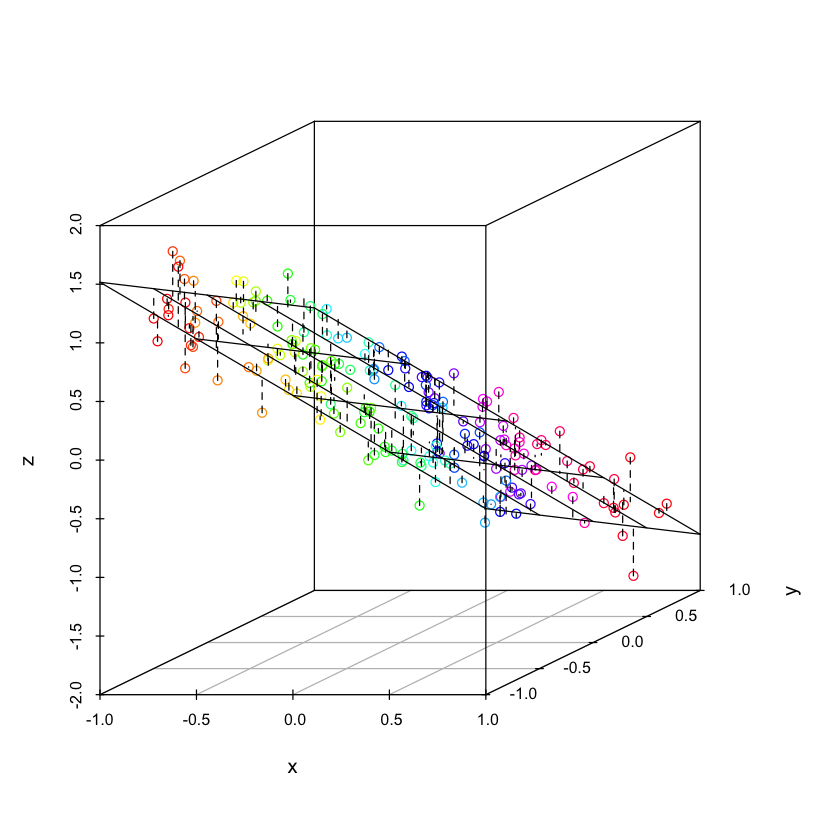

In [5]:
m <- 200       # number of samples

# 1. Generate the data - we will create a 2D plane that will be placed into a 3D space
x <- runif(m, -1, 1)
y <- runif(m, -1, 1)
plane <- cbind(x, y, z=-x - 0.5*y) # the plane is: x + 0.5y + z=0, the normal vector is (1,0.5,1) 
plane <- plane[order(plane[,"x"] + plane[,"y"]),] # sort observations to be able to visually understand them

# 2. Add noise to our plane
sigma <- 0.2   # standard deviation for the noisy manifolds

noisyPlane <- plane
noisyPlane[, "z"] <- noisyPlane[, "z"] + rnorm(n=m, mean=0, sd=sigma)

# 3. Plot the data
scatterplot3d(noisyPlane, color=rainbow(nrow(plane)))

# 4. Add the ideal 2D plane grid for better visualization
s3d <- scatterplot3d(noisyPlane, color=rainbow(nrow(plane)))

recoveredPlane <- lm(z ~ ., as.data.frame(noisyPlane)) # a linear model will serve as a prescription for the plane grid
s3d$plane3d(recoveredPlane, lty="solid")               # add the ideal plane to the plot

# 5. Add deviations of the noisy points from the ideal plane
noisy.3d <- s3d$xyz.convert(noisyPlane[,"x"], noisyPlane[,"y"], noisyPlane[,"z"])  # locations of data points
flat.3d <- s3d$xyz.convert(noisyPlane[,"x"], noisyPlane[,"y"], plane[,"z"])        # corresponding locations on the regression plane
segments(noisy.3d$x, noisy.3d$y, flat.3d$x, flat.3d$y, lty="dashed")               # draw lines from data points to plane

Importance of components:
                          PC1    PC2    PC3
Standard deviation     0.8373 0.5892 0.1268
Proportion of Variance 0.6587 0.3261 0.0151
Cumulative Proportion  0.6587 0.9849 1.0000

PC1,PC2,PC3
-1.4683732,0.49075810,0.186518925
-1.5495795,0.34493096,0.046921129
-1.8682196,0.45517168,-0.278372136
-1.4718776,0.01845560,0.185580237
-1.6093939,0.19065877,-0.003457399
-1.5469377,0.28031355,-0.055153455
-1.3771701,0.31807978,0.067109712
-1.4656506,-0.01956787,0.100548712
-1.2999389,0.36657047,0.077893676
-1.2273891,0.22305206,0.181327810


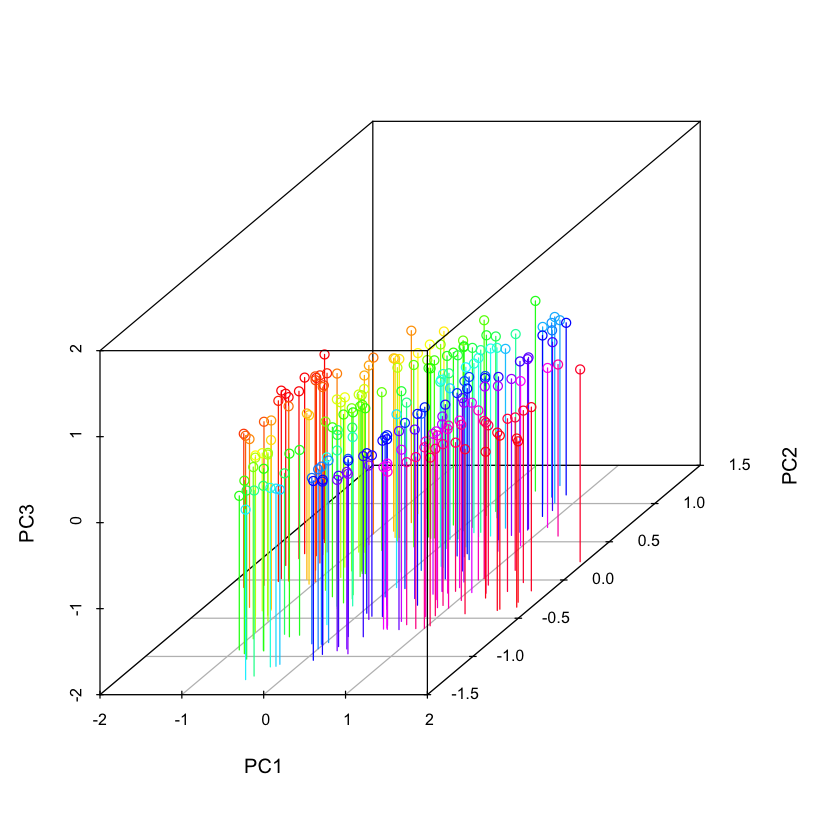

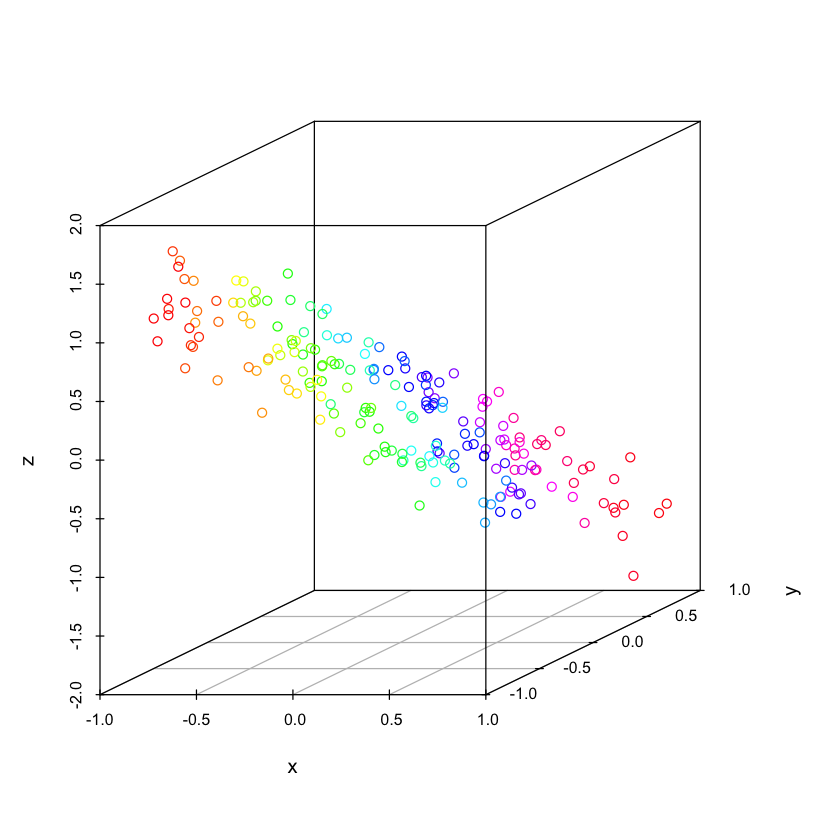

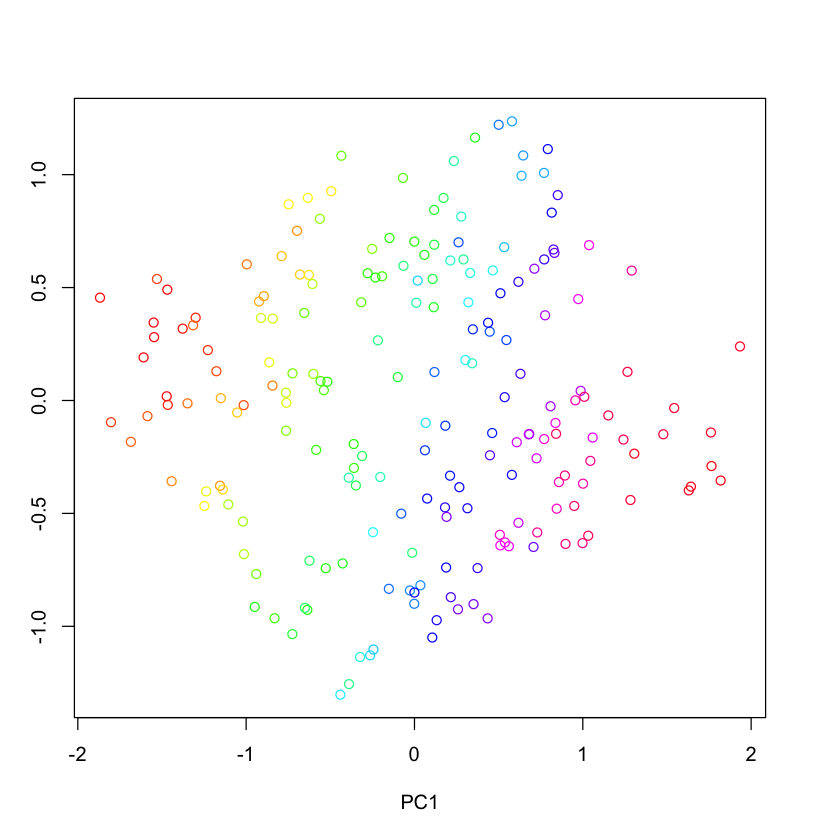

In [8]:
# PCA call
pca_res <- prcomp(noisyPlane) 
# With real data, you will want to set the argument *scale=True*

# Use the almighty summary() function to look at the PCA results
# Question: What information does it tell us? 
summary(pca_res)

# Question: the PCA result has the field called "x". What do you think it represents?
pca_res$x
# Maybe plotting the field and comparing it with the original data will help
scatterplot3d(pca_res$x, color=rainbow(nrow(plane)), zlim = c(-2, 2), type = "h") 
scatterplot3d(noisyPlane, color=rainbow(nrow(plane)))
# Question: Why the PCA result is in 3D if it's supposed to reduce dimensions?

# Now plot the first two columns of the PCA "x" table. Are the dimensions of data what you would expect from PCA?
plot(pca_res$x, col=rainbow(nrow(plane)), ylab = "PC2") 

,PC1,PC2,PC3
x,0.5463717,0.51433457,-0.6610128
y,0.3493915,-0.85724529,-0.3782276
z,-0.7611856,-0.02429945,-0.6480787


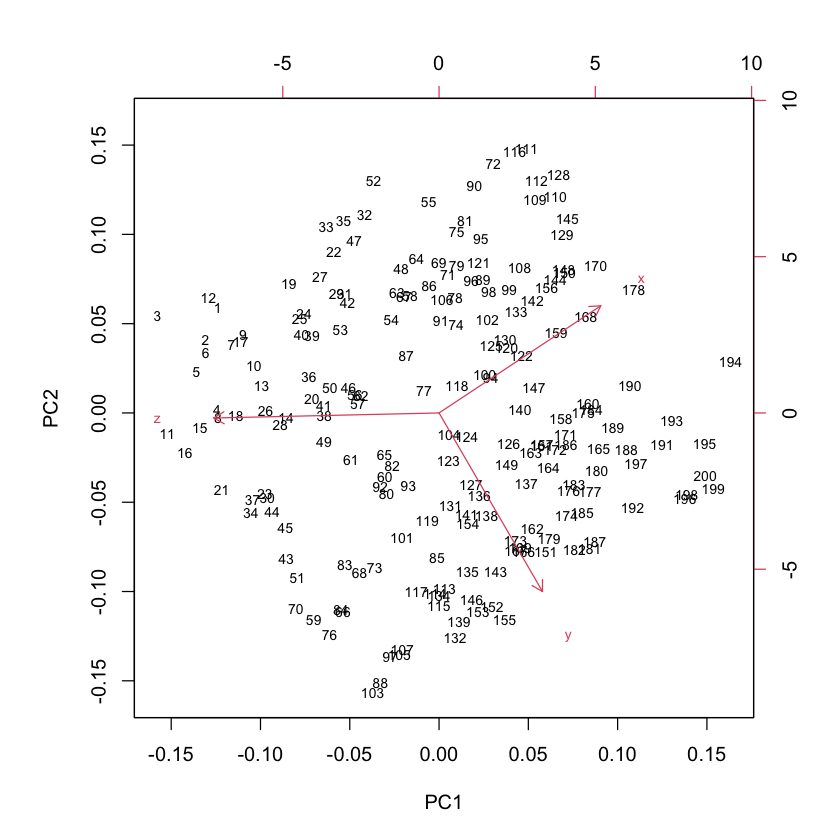

In [9]:
# An important output of PCA is the transformation matrix, accessible in the field "rotation"
pca_res$rotation 

# Question: Can you guess, how the matrix transforms/projects the original space?
# Maybe this plot will help:
biplot(pca_res, cex=0.7) 

In [ ]:
## Let's try to compute the matrix "x" (the transformed data) by hand

# First, calculate the "rotation" matrix by hand 
# It consists of eigen-vectors of the co-variance matrix of your data. 
# Use the eigen() and cov() functions. Compare with the reference rotation matrix
transform_mat <- ___

my_x <- ___      # Transform the original data by hand (multiply your data with the transformation matrix)
my_x_centr <- scale(my_x, center = T, scale = F) # Center the transformed dataset (this is what prcomp() does too)
round(my_x_centr - pca_res$x) %>% head()  # Compare it with the reference projection. They should be the same

## Can we reconstruct the original data from transformed "x"? Of course, PCA is a loss-less transformation
noisyPlane_reconstr <- my_x %*% t(transform_mat) 
round(noisyPlane_reconstr - noisyPlane) %>% head() # Compare reconstruction with original data. The should be the same
# Why we need to multiply our projection with the transpose of rotation matrix:
# https://stats.stackexchange.com/questions/229092/how-to-reverse-pca-and-reconstruct-original-variables-from-several-principal-com

In [ ]:
## Here, we perform dimensionality reduction by discarding PC3. 
noisyPlane_reduced <- pca_res$x[, 1:2]
# What happens, if we try to reconstruct the original 3D space using this 2D projection??
# Again, reconstruct by the inverse of transformation matrix (take care of dimensions!)
noisyPlane_2d_reconstr <- noisyPlane_reduced %*% t(___)

# Now let's see, how the reconstruction went
s3d <- scatterplot3d(noisyPlane)  # Plot original points as black circles
s3d$points3d(noisyPlane_2d_reconstr, col=rainbow(m), pch=4)  # Add the reconstruction from 2D data
recovered.3d <- s3d$xyz.convert(noisyPlane_2d_reconstr[,"x"], noisyPlane_2d_reconstr[,"y"], noisyPlane_2d_reconstr[,"z"])  
flat.3d <- s3d$xyz.convert(noisyPlane_2d_reconstr[,"x"], noisyPlane_2d_reconstr[,"y"], fitted(recoveredPlane)) # corresponding locations on the regression plane
segments(recovered.3d$x, recovered.3d$y, flat.3d$x, flat.3d$y, lty="dashed")  # draw lines from data points to plane


In [ ]:
{r echo=FALSE}
#' Calculate mean reconstruction error
#'
#' @param x the original sample matrix (samples in rows, features in columns)
#' @param r the sample matrix after reconstruction (samples in rows, features in columns), the same dimension as x
#' @return the mean reconstruction error
#' @export
recError <- function(x, r){
  if (sum(dim(x)==dim(r)) != 2){stop("Different dimensions!")}
  recError <- 0
  for (i in 1:nrow(x)){
    # The error is Euclidean distance between reconstruction and original position
    recError <- recError + sqrt(sum((x[i,] - r[i,])^2))
  }
  return(recError / nrow(x))
}

In [ ]:
set.seed(42)
D = 3         # number of input dimensions

dirs <- rmvnorm(n = m, mean = rep(0, D)) # sample
colnames(dirs) <- c("x","y","z")
sphere <- dirs / sqrt(rowSums(dirs^2)) # normalize
sphere <- sphere[order(sphere[,"z"]+cos(sphere[,"x"])+cos(sphere[,"y"])),] # sort observations to be able to visually understand them
noisySphere <- sphere + rmvnorm(n = m, mean = rep(0, D), sigma = sigma/20 * diag(D)) # add noise

# Plot an "ideal" sphere and version with added noise
scatterplot3d(sphere,color=rainbow(m))
scatterplot3d(noisySphere,color=rainbow(m))

In [ ]:
pca_noisySphere <- prcomp(noisySphere) 
# get info about projection
summary(pca_noisySphere) 
# notice the first component captures only slightly more than 1/3 of variance!
# considering we have 3D space, and arbitrary "best" axis would capture at worst 1/3 variation too. 

biplot(pca_noisySphere,cex=0.7)

# see the projection in the transformed space, no reduction
scatterplot3d(pca_noisySphere$x, color=rainbow(nrow(sphere)), zlim = c(-2,2)) 

## Dimensionality reduction - discard PC3. 
noisySphere_reduced <- pca_noisySphere$x[, 1:2]
# see the projection in the transformed space, this time with reduction to 2D
plot(noisySphere_reduced, col=rainbow(nrow(sphere)), ylab = "PC2") 

# Reconstruction of the original 3D space from 2D projection will not go as well as in case of the plane. 
# Prepare data first
noisySphere_2d_reconstr <- noisySphere_reduced %*% t(pca_noisySphere$rotation[, 1:2])
# Now let's wee, how the reconstruction went
s3d <- scatterplot3d(noisySphere)  # Plot original points as black circles
s3d$points3d(noisySphere_2d_reconstr, col=rainbow(m), pch=4)  # Add the reconstruction from 2D data
recovered.3d <- s3d$xyz.convert(noisySphere_2d_reconstr[,"x"], noisySphere_2d_reconstr[,"y"], noisySphere_2d_reconstr[,"z"])  

orig.3d <- s3d$xyz.convert(sphere[,"x"],sphere[,"y"], sphere[,"z"]) # the original sphere
segments(recovered.3d$x, recovered.3d$y, orig.3d$x, orig.3d$y, lty="dashed")  # draw lines from data points to Sphere